# Citi Bike NYC 2022: Demand, Forecasting and Network Coverage

An end-to-end analysis of every Citi Bike trip taken in New York City in 2022 (29.8M trips):
cleaning, exploratory analysis, time series decomposition, stationarity testing,
forecasting (moving average, ARIMA, SARIMA) with a rolling backtest, anomaly detection,
geospatial coverage analysis and origin-destination flows.

Built for *Emerging Topics in Data Analysis & Management*, IE University (Madrid), Spring 2026.

The raw trip files are ~6 GB, so `scripts/build_dataset.py` aggregates them once into the small
tables in `data/processed/`. Everything below runs from those tables in under a minute.

In [1]:
import json
import warnings
from pathlib import Path

import geopandas as gpd
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
import requests
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.stattools import adfuller

warnings.filterwarnings("ignore")
pd.set_option("display.width", 120)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA = ROOT / "data"
FIG = ROOT / "figures"
FIG.mkdir(exist_ok=True)

ACCENT, GREY, RED, GREEN = "#1f6feb", "#8b949e", "#cf222e", "#1a7f37"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "axes.titleweight": "bold",
    "axes.titlesize": 12, "font.size": 10,
})
thousands = mticker.FuncFormatter(lambda x, _: f"{x/1000:,.0f}k" if x else "0")

def save(fig, name):
    fig.savefig(FIG / f"{name}.png")
    plt.show()

## 1. Data and cleaning

Source: [Citi Bike system data](https://citibikenyc.com/system-data), January to December 2022.
Each record is one trip with start/end time, start/end station and coordinates, bike type and rider type.

Cleaning rules (applied in `build_dataset.py`):
- **Negative durations** (end before start) are system errors.
- **Trips under 60 seconds** are false starts: a bike undocked and immediately returned.
- **Trips over 24 hours** are lost, stolen or unreturned bikes, not real journeys.
- **Missing start or end station** can't be placed on the network.

In [2]:
log = json.loads((DATA / "processed" / "cleaning_log.json").read_text())
removed = {k: log[k] for k in ["negative_duration", "under_60s", "over_24h", "missing_station"]}
cleaning = pd.DataFrame({"trips_removed": removed})
cleaning["share_of_raw"] = (cleaning["trips_removed"] / log["raw_trips"]).map("{:.3%}".format)
print(f"Raw trips:   {log['raw_trips']:>12,}")
print(f"Clean trips: {log['clean_trips']:>12,}  ({1 - log['clean_trips']/log['raw_trips']:.2%} removed)\n")
print(cleaning.to_string())
print("\nTrip duration percentiles (minutes):")
print({k: round(v / 60, 1) for k, v in log["duration_percentiles_s"].items()})

Raw trips:     29,838,166
Clean trips:   29,766,034  (0.24% removed)

                   trips_removed share_of_raw
negative_duration            357       0.001%
under_60s                     14       0.000%
over_24h                   39772       0.133%
missing_station            31989       0.107%

Trip duration percentiles (minutes):
{'p1': 1.4, 'p5': 2.5, 'p25': 5.8, 'p50': 10.2, 'p75': 18.0, 'p95': 39.9, 'p99': 82.8}


In [3]:
daily = pd.read_csv(DATA / "processed" / "daily_trips.csv", parse_dates=["date"]).set_index("date")
daily = daily.asfreq("D")
y = daily["trips"].astype(float)
hourly = pd.read_csv(DATA / "processed" / "hourly_trips.csv")
stations = pd.read_csv(DATA / "processed" / "stations.csv")
od = pd.read_parquet(DATA / "processed" / "od_pairs.parquet")
print(f"{len(y)} days, {y.isna().sum()} missing | mean {y.mean():,.0f} trips/day | "
      f"min {y.min():,.0f} ({y.idxmin():%b %d}) | max {y.max():,.0f} ({y.idxmax():%b %d})")
print(f"{len(stations):,} stations | {len(od):,} origin-destination pairs with 5+ trips")

365 days, 0 missing | mean 81,551 trips/day | min 2,809 (Jan 29) | max 134,848 (Sep 14)
1,761 stations | 482,148 origin-destination pairs with 5+ trips


## 2. Exploratory analysis

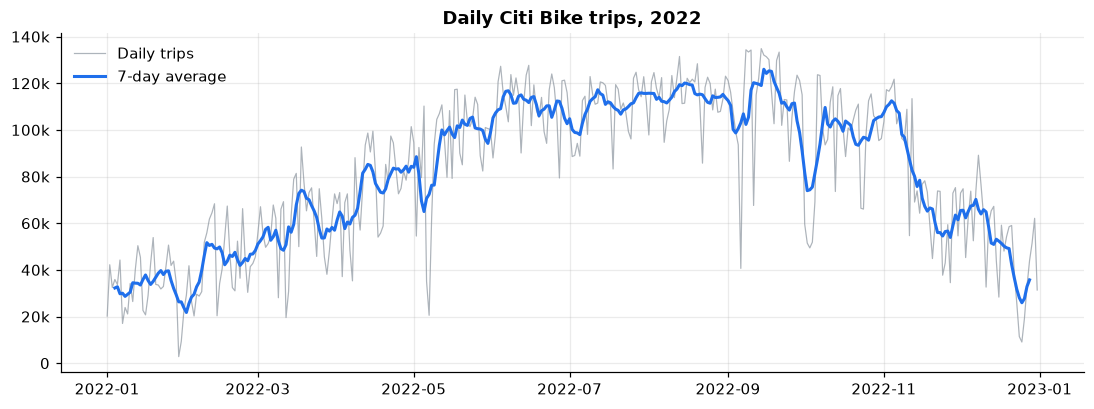

Busiest month: August (115,024/day) | quietest: January (32,738/day) | ratio 3.5x


In [4]:
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(y.index, y, color=GREY, lw=0.8, alpha=0.7, label="Daily trips")
ax.plot(y.index, y.rolling(7, center=True).mean(), color=ACCENT, lw=2, label="7-day average")
ax.yaxis.set_major_formatter(thousands)
ax.set_title("Daily Citi Bike trips, 2022")
ax.legend(frameon=False, loc="upper left")
save(fig, "daily_trips")

monthly = y.resample("ME").mean()
print(f"Busiest month: {monthly.idxmax():%B} ({monthly.max():,.0f}/day) | "
      f"quietest: {monthly.idxmin():%B} ({monthly.min():,.0f}/day) | ratio {monthly.max()/monthly.min():.1f}x")

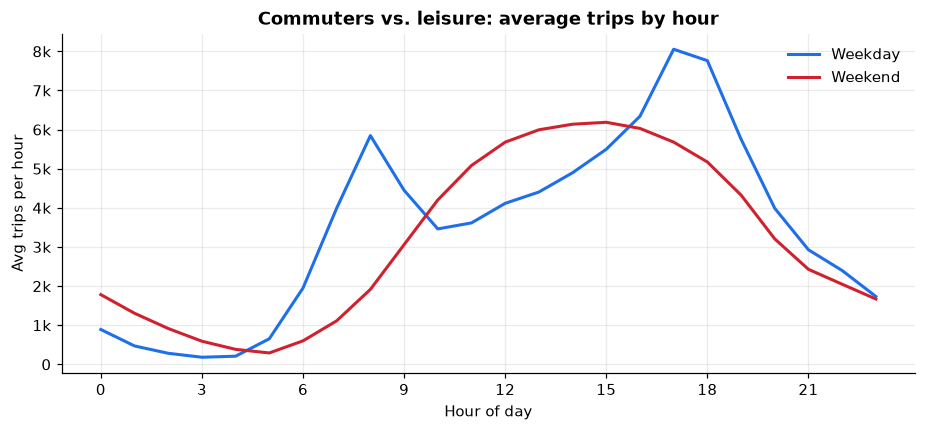

Weekday peaks: 8:00 and 17:00 | weekend peak: 15:00


In [5]:
n_days = daily.index.dayofweek.isin([5, 6])
days = {False: (~n_days).sum(), True: n_days.sum()}
prof = hourly.groupby(["is_weekend", "hour"])["trips"].sum().unstack(0)
prof = prof / pd.Series(days)
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(prof.index, prof[False], color=ACCENT, lw=2, label="Weekday")
ax.plot(prof.index, prof[True], color=RED, lw=2, label="Weekend")
ax.set_xticks(range(0, 24, 3))
ax.set_xlabel("Hour of day")
ax.set_ylabel("Avg trips per hour")
ax.yaxis.set_major_formatter(thousands)
ax.set_title("Commuters vs. leisure: average trips by hour")
ax.legend(frameon=False)
save(fig, "hourly_profile")

wk = prof[False]
print(f"Weekday peaks: {wk.loc[:11].idxmax()}:00 and {wk.loc[12:].idxmax()}:00 | weekend peak: {prof[True].idxmax()}:00")

In [6]:
riders = daily[["member_trips", "casual_trips"]].resample("ME").sum()
share_casual = riders["casual_trips"] / riders.sum(axis=1)
by_type = hourly.groupby(["member_casual", "is_weekend"])["trips"].sum().unstack()
weekend_share = by_type[True] / by_type.sum(axis=1)
print("Casual riders' share of trips by month:")
print(share_casual.map("{:.0%}".format).set_axis(share_casual.index.strftime("%b")).to_string())
print(f"\nShare of trips on weekends: members {weekend_share['member']:.0%}, casual {weekend_share['casual']:.0%}")
print(f"Electric bike share: {daily['electric_trips'].sum() / daily['trips'].sum():.0%} of all trips")

Casual riders' share of trips by month:
date
Jan    14%
Feb    16%
Mar    20%
Apr    25%
May    23%
Jun    24%
Jul    24%
Aug    25%
Sep    23%
Oct    21%
Nov    18%
Dec    14%

Share of trips on weekends: members 24%, casual 37%
Electric bike share: 39% of all trips


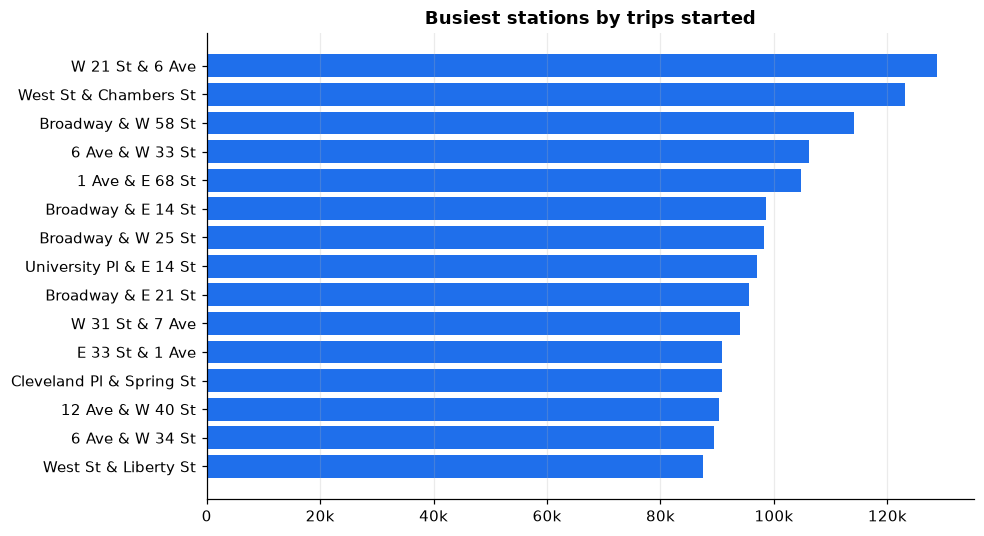

In [7]:
top = stations.nlargest(15, "starts").set_index("name")["starts"].sort_values()
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.barh(top.index, top.values, color=ACCENT)
ax.xaxis.set_major_formatter(thousands)
ax.set_title("Busiest stations by trips started")
ax.grid(axis="y", visible=False)
save(fig, "top_stations")

## 3. Time series decomposition

Daily demand has an obvious weekly cycle riding on an annual one. With one year of data the annual
cycle can't be estimated as a seasonal component, so the decomposition uses a 7-day period and the
annual swing lands in the trend. Because the weekly swing grows with the level (summer weekdays vs.
weekends differ by far more trips than winter ones), a multiplicative model should fit better.

Relative residual spread: additive 0.528 | multiplicative 0.235 -> multiplicative fits better


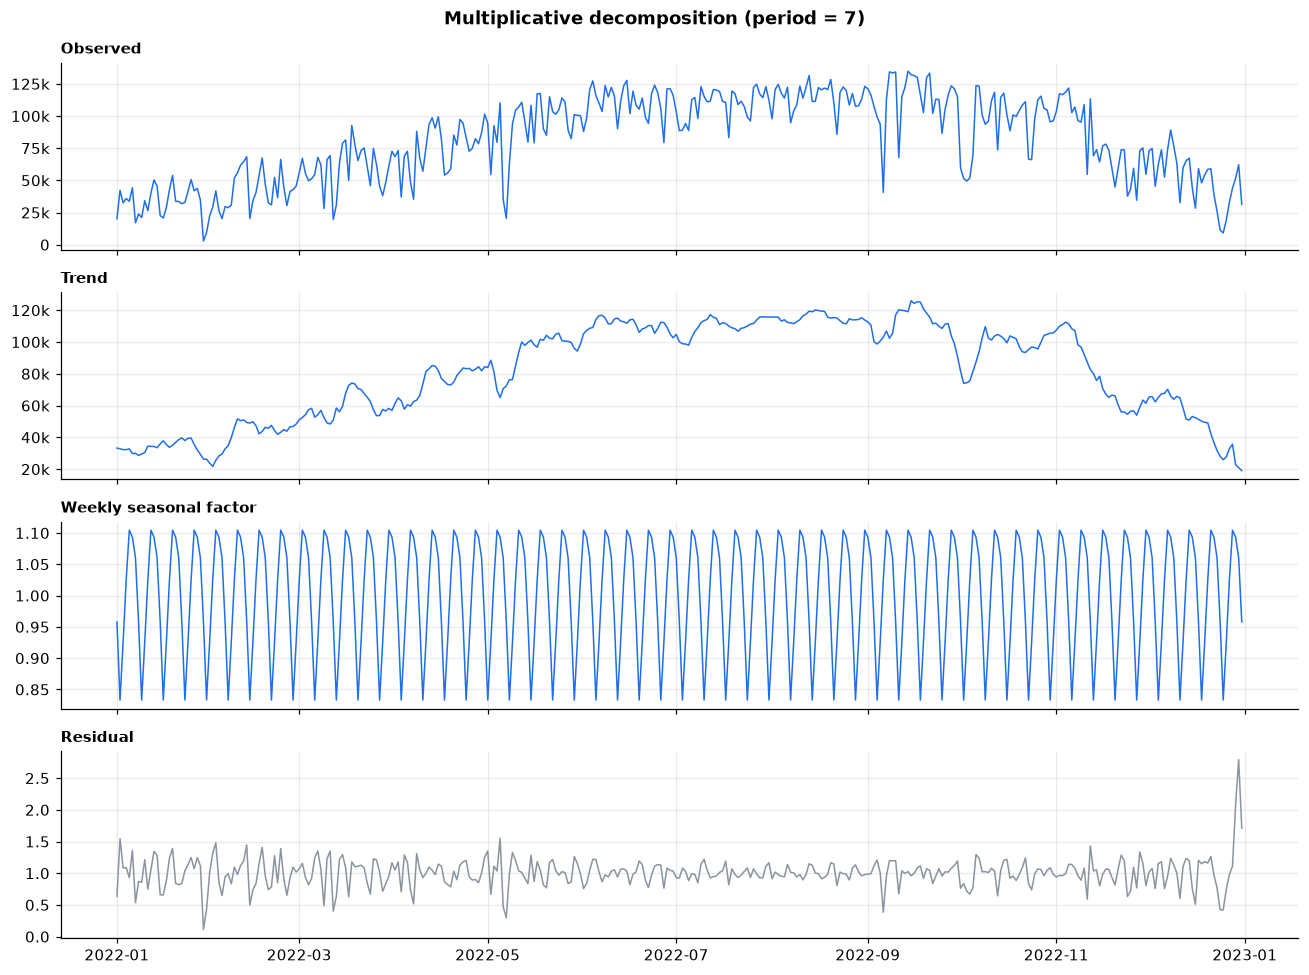

In [8]:
dec_add = seasonal_decompose(y, model="additive", period=7, extrapolate_trend="freq")
dec_mul = seasonal_decompose(y, model="multiplicative", period=7, extrapolate_trend="freq")
# Compare on the same scale: residual error as a share of the level.
rel_add = (dec_add.resid / y).std()
rel_mul = (dec_mul.resid - 1).std()
print(f"Relative residual spread: additive {rel_add:.3f} | multiplicative {rel_mul:.3f} -> "
      f"{'multiplicative' if rel_mul < rel_add else 'additive'} fits better")

fig, axes = plt.subplots(4, 1, figsize=(12, 9), sharex=True)
for ax, (s, title) in zip(axes, [(y, "Observed"), (dec_mul.trend, "Trend"),
                                 (dec_mul.seasonal, "Weekly seasonal factor"), (dec_mul.resid, "Residual")]):
    ax.plot(s.index, s, color=ACCENT if title != "Residual" else GREY, lw=1)
    ax.set_title(title, loc="left", fontsize=10)
axes[0].yaxis.set_major_formatter(thousands)
axes[1].yaxis.set_major_formatter(thousands)
fig.suptitle("Multiplicative decomposition (period = 7)", fontweight="bold")
fig.tight_layout()
save(fig, "decomposition")

In [9]:
dow = y.groupby(y.index.day_name()).mean().reindex(
    ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"])
factor = dec_mul.seasonal.groupby(dec_mul.seasonal.index.day_name()).mean().reindex(dow.index)
print(pd.DataFrame({"avg_trips": dow.round(0).astype(int), "seasonal_factor": factor.round(3)}).to_string())

           avg_trips  seasonal_factor
date                                 
Monday         75106            0.926
Tuesday        83068            1.025
Wednesday      89000            1.104
Thursday       86801            1.093
Friday         85403            1.060
Saturday       80449            0.958
Sunday         71049            0.833


## 4. Stationarity

ARIMA-family models assume a stationary series (constant mean and variance). Checked three ways:
rolling statistics, the Augmented Dickey-Fuller test, and autocorrelation plots.

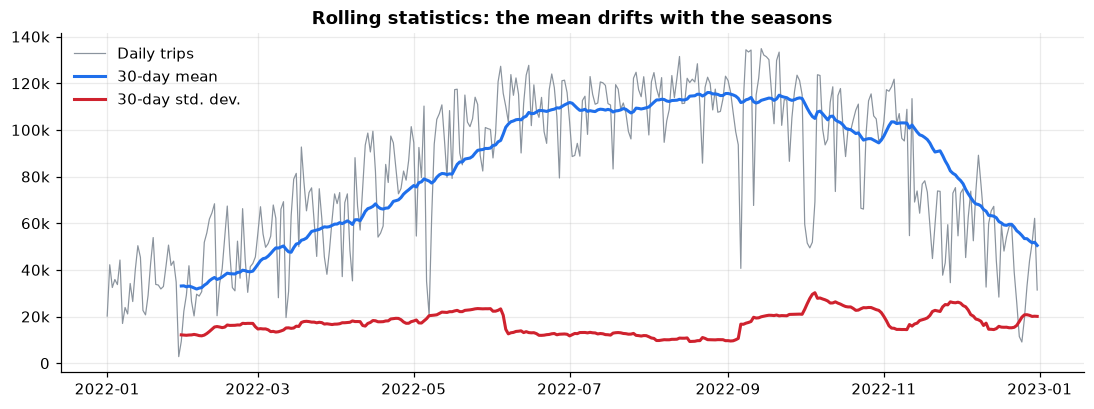

In [10]:
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(y, color=GREY, lw=0.8, label="Daily trips")
ax.plot(y.rolling(30).mean(), color=ACCENT, lw=2, label="30-day mean")
ax.plot(y.rolling(30).std(), color=RED, lw=2, label="30-day std. dev.")
ax.yaxis.set_major_formatter(thousands)
ax.set_title("Rolling statistics: the mean drifts with the seasons")
ax.legend(frameon=False, loc="upper left")
save(fig, "rolling_stats")

In [11]:
def adf(series, label):
    stat, p, lags, nobs, crit, _ = adfuller(series.dropna(), autolag="AIC")
    verdict = "stationary" if p < 0.05 else "NON-stationary"
    print(f"{label:<22} ADF = {stat:7.3f}  p = {p:.4f}  (5% critical {crit['5%']:.2f})  -> {verdict}")

adf(y, "Original series")
adf(y.diff(), "First difference")
adf(y.diff(7), "Weekly difference")
adf(y.diff().diff(7), "First + weekly diff.")

Original series        ADF =  -1.822  p = 0.3696  (5% critical -2.87)  -> NON-stationary
First difference       ADF = -13.545  p = 0.0000  (5% critical -2.87)  -> stationary
Weekly difference      ADF =  -4.985  p = 0.0000  (5% critical -2.87)  -> stationary
First + weekly diff.   ADF =  -8.836  p = 0.0000  (5% critical -2.87)  -> stationary


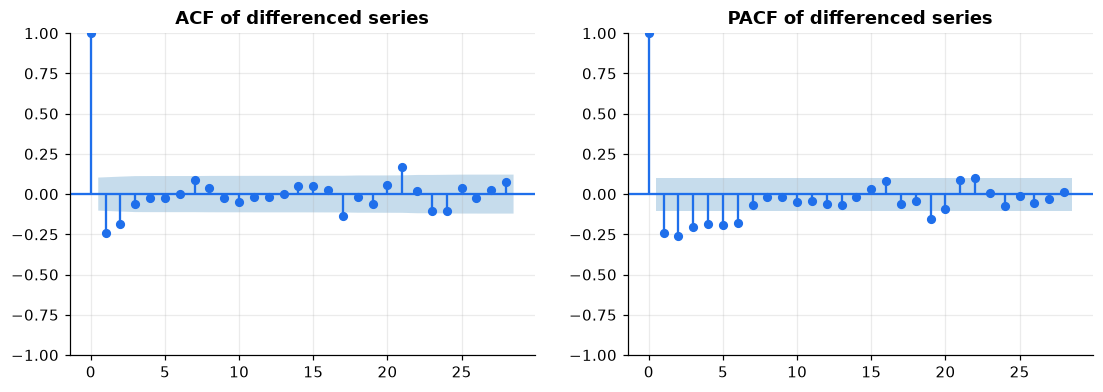

Autocorrelation of raw series at lags 1/7/14/30: [0.837, 0.751, 0.697, 0.586]


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
plot_acf(y.diff().dropna(), lags=28, ax=axes[0], color=ACCENT, vlines_kwargs={"colors": ACCENT})
plot_pacf(y.diff().dropna(), lags=28, ax=axes[1], color=ACCENT, vlines_kwargs={"colors": ACCENT}, method="ywm")
axes[0].set_title("ACF of differenced series")
axes[1].set_title("PACF of differenced series")
save(fig, "acf_pacf")

acf_raw = [round(float(y.autocorr(l)), 3) for l in (1, 7, 14, 30)]
print("Autocorrelation of raw series at lags 1/7/14/30:", acf_raw)

The level series fails ADF; one difference makes it stationary (d = 1). Spikes at lags 7, 14, 21
in the ACF point to a weekly seasonal term, which motivates SARIMA with s = 7.

## 5. Forecasting

**Setup from the course assignment:** train on 90 days, forecast the next 7. The assignment used
the final week of the year (Dec 25-31). That one week is a holiday week, so the result says more about
holidays than about the models. To judge them fairly, section 5.2 repeats the exercise from 30
different forecast origins across the year.

Models:
- **Seasonal naive:** next Monday = last Monday. The baseline any model has to beat.
- **Moving average (7 and 30 days):** a flat forecast at the recent mean.
- **ARIMA(4,1,3):** short-memory autoregressive model, no explicit weekly term.
- **SARIMA(1,1,1)x(1,0,1,7):** adds the weekly seasonal component.

In [13]:
def metrics(actual, pred):
    actual, pred = np.asarray(actual), np.asarray(pred)
    err = actual - pred
    return {"RMSE": np.sqrt((err ** 2).mean()), "MAE": np.abs(err).mean(),
            "MAPE %": (np.abs(err) / actual).mean() * 100}

def forecast_all(train, h=7):
    out = {
        "Seasonal naive": np.tile(train.iloc[-7:].values, int(np.ceil(h / 7)))[:h],
        "7-day moving avg": np.repeat(train.iloc[-7:].mean(), h),
        "30-day moving avg": np.repeat(train.iloc[-30:].mean(), h),
    }
    tr = train.reset_index(drop=True)
    out["ARIMA(4,1,3)"] = ARIMA(tr, order=(4, 1, 3)).fit().forecast(h).values
    out["SARIMA(1,1,1)x(1,0,1,7)"] = SARIMAX(
        tr, order=(1, 1, 1), seasonal_order=(1, 0, 1, 7),
        enforce_stationarity=False, enforce_invertibility=False,
    ).fit(disp=False).forecast(h).values
    return out

TRAIN, H = 90, 7

### 5.1 Original holdout: Dec 25-31

Train Sep 26 - Dec 24 | test Dec 25 - Dec 31

                            RMSE      MAE  MAPE %
SARIMA(1,1,1)x(1,0,1,7)  16435.2  13697.0    65.1
ARIMA(4,1,3)             16702.1  13969.7    68.4
7-day moving avg         18236.9  15323.6    86.3
30-day moving avg        26387.7  21955.9   128.9
Seasonal naive           28025.6  26202.3   124.5


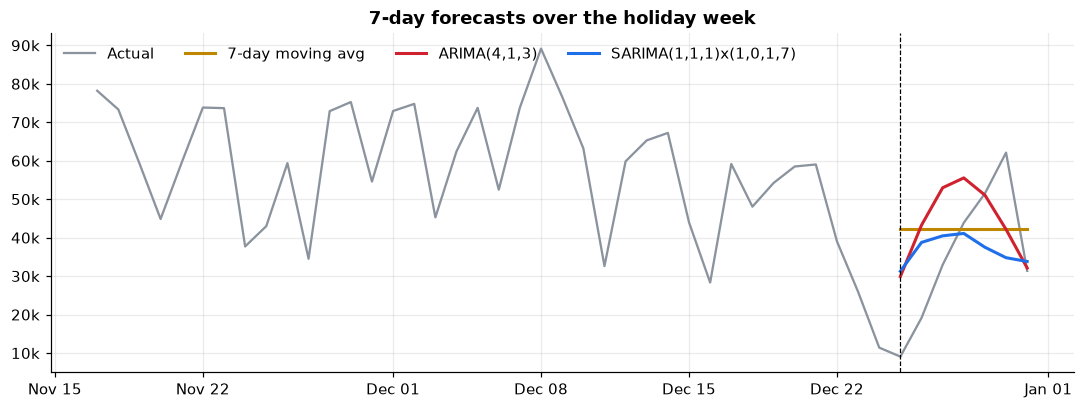

In [14]:
train, test = y.iloc[-(TRAIN + H):-H], y.iloc[-H:]
preds = forecast_all(train, H)
holdout = pd.DataFrame({m: metrics(test, p) for m, p in preds.items()}).T.round(1)
print(f"Train {train.index[0]:%b %d} - {train.index[-1]:%b %d} | test {test.index[0]:%b %d} - {test.index[-1]:%b %d}\n")
print(holdout.sort_values("RMSE").to_string())

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(y.iloc[-45:], color=GREY, lw=1.5, label="Actual")
for (m, p), c in zip(preds.items(), [GREY, "#bf8700", "#8250df", RED, ACCENT]):
    if m in ("Seasonal naive", "30-day moving avg"):
        continue
    ax.plot(test.index, p, lw=2, color=c, label=m)
ax.axvline(test.index[0], color="black", lw=0.8, ls="--")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
ax.yaxis.set_major_formatter(thousands)
ax.set_title("7-day forecasts over the holiday week")
ax.legend(frameon=False, ncol=4, loc="upper left")
save(fig, "forecast_holdout")

### 5.2 Rolling-origin backtest

30 forecast origins spaced 7 days apart, ending at the original holdout. Each fit uses only the
90 days before its origin, so there's no look-ahead.

In [15]:
ends = [len(y) - H - 7 * k for k in range(30)][::-1]
rows = []
for end in ends:
    tr, te = y.iloc[end - TRAIN:end], y.iloc[end:end + H]
    for m, p in forecast_all(tr, H).items():
        rows.append({"origin": te.index[0], "model": m, **metrics(te, p)})
bt = pd.DataFrame(rows)

summary = bt.groupby("model")[["RMSE", "MAE", "MAPE %"]].mean().sort_values("MAE")
wins = bt.loc[bt.groupby("origin")["MAE"].idxmin(), "model"].value_counts().reindex(summary.index).fillna(0)
summary["weeks won (MAE)"] = wins.astype(int)
print(f"{bt['origin'].nunique()} weekly origins, {bt['origin'].min():%b %d} to {bt['origin'].max():%b %d}\n")
print(summary.round(1).to_string())

30 weekly origins, Jun 05 to Dec 25

                            RMSE      MAE  MAPE %  weeks won (MAE)
model                                                             
SARIMA(1,1,1)x(1,0,1,7)  17280.7  14010.3    22.6                8
7-day moving avg         17179.6  14171.2    22.5                2
ARIMA(4,1,3)             17715.8  14524.9    22.9                6
30-day moving avg        18454.0  15231.2    26.6                8
Seasonal naive           20873.2  16873.7    26.7                6


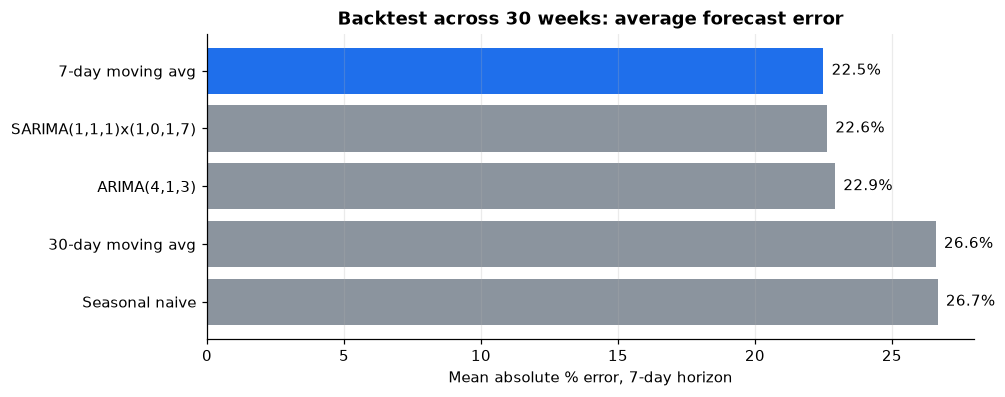

In [16]:
fig, ax = plt.subplots(figsize=(9, 3.6))
s = summary["MAPE %"].sort_values()
ax.barh(s.index, s.values, color=[ACCENT if i == 0 else GREY for i in range(len(s))])
for i, v in enumerate(s.values):
    ax.text(v + 0.3, i, f"{v:.1f}%", va="center")
ax.invert_yaxis()
ax.set_xlabel("Mean absolute % error, 7-day horizon")
ax.set_title("Backtest across 30 weeks: average forecast error")
ax.grid(axis="y", visible=False)
save(fig, "backtest")

## 6. Anomaly detection

Three independent methods, and a day is flagged only when at least two agree:
1. **Model residuals:** |z| > 2.5 on the residuals of a SARIMA fitted to the whole year.
2. **IQR fences** on the weekly-adjusted series (raw counts would only flag summer and winter).
3. **Rolling deviation:** |z| > 2.5 against the trailing 30-day mean and spread.

In [17]:
full_fit = SARIMAX(y, order=(1, 1, 1), seasonal_order=(1, 0, 1, 7),
                   enforce_stationarity=False, enforce_invertibility=False).fit(disp=False)
resid = full_fit.resid.iloc[14:]
z_resid = (resid - resid.mean()) / resid.std()

adj = y / dec_mul.seasonal / dec_mul.trend
q1, q3 = adj.quantile([0.25, 0.75])
iqr_flag = (adj < q1 - 1.5 * (q3 - q1)) | (adj > q3 + 1.5 * (q3 - q1))

roll_mu, roll_sd = y.rolling(30).mean().shift(1), y.rolling(30).std().shift(1)
z_roll = (y - roll_mu) / roll_sd

flags = pd.DataFrame({
    "trips": y, "resid_z": z_resid, "roll_z": z_roll,
    "m1": z_resid.abs() > 2.5, "m2": iqr_flag, "m3": z_roll.abs() > 2.5,
}).fillna({"m1": False, "m3": False})
flags["votes"] = flags[["m1", "m2", "m3"]].sum(axis=1)
anom = flags[flags["votes"] >= 2].copy()
anom["direction"] = np.where(anom["resid_z"] < 0, "low", "high")
print(f"Flags: residual {flags.m1.sum()}, IQR {flags.m2.sum()}, rolling {flags.m3.sum()} | consensus {len(anom)}\n")
print(anom.assign(day=anom.index.strftime("%a %b %d"))[["day", "trips", "resid_z", "roll_z", "votes", "direction"]]
      .round(2).to_string(index=False))

Flags: residual 7, IQR 19, rolling 10 | consensus 8

       day   trips  resid_z  roll_z votes direction
Fri May 06 35104.0    -4.09   -2.42     2       low
Sat May 07 20530.0    -2.59   -3.04     3       low
Tue Sep 06 40639.0    -4.18   -6.87     3       low
Sun Sep 11 67612.0    -2.87   -2.59     2       low
Sat Oct 01 59599.0    -3.48   -2.57     2       low
Fri Nov 11 54669.0    -3.37   -3.35     2       low
Sat Dec 24 11407.0    -1.78   -2.80     2       low
Sun Dec 25  9070.0    -0.72   -2.62     2       low


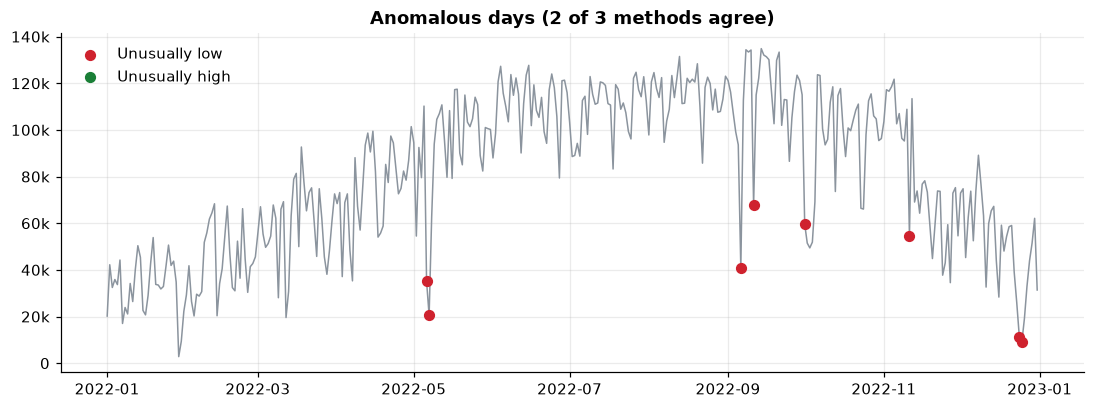

In [18]:
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(y, color=GREY, lw=1)
lo, hi = anom[anom.direction == "low"], anom[anom.direction == "high"]
ax.scatter(lo.index, lo.trips, color=RED, zorder=3, s=40, label="Unusually low")
ax.scatter(hi.index, hi.trips, color=GREEN, zorder=3, s=40, label="Unusually high")
ax.yaxis.set_major_formatter(thousands)
ax.set_title("Anomalous days (2 of 3 methods agree)")
ax.legend(frameon=False, loc="upper left")
save(fig, "anomalies")

Most low anomalies line up with heavy rain or holidays: weather explains the sharpest one-day drops
in bike demand, and it isn't in this dataset. That is the most valuable feature to add next.

## 7. The network today (CityBikes API)

A live snapshot of Citi Bike from the public [CityBikes API](https://api.citybik.es/v2/), for
comparison with the 2022 network. This cell runs at execution time, so the numbers change.

In [19]:
try:
    net = requests.get("https://api.citybik.es/v2/networks/citi-bike-nyc", timeout=20).json()["network"]
    live = pd.DataFrame(net["stations"])
    print(f"Snapshot of {net['name']} ({len(live):,} stations): "
          f"{live['free_bikes'].sum():,} bikes available, {live['empty_slots'].sum():,} empty docks")
    print(f"Stations in 2022 trip data: {len(stations):,} -> today: {len(live):,} "
          f"({len(live) / len(stations) - 1:+.0%})")
except Exception as e:
    print(f"CityBikes API unavailable: {e}")

Snapshot of Citi Bike (2,464 stations): 34,644 bikes available, 30,876 empty docks
Stations in 2022 trip data: 1,761 -> today: 2,464 (+40%)


## 8. Geospatial coverage

How much of each borough is within a 5-minute walk (400 m) of a station? Coordinates are stored
in WGS84 (EPSG:4326) and projected to UTM zone 18N (EPSG:32618) so buffers and areas are in metres.

In [20]:
gst = gpd.GeoDataFrame(stations, geometry=gpd.points_from_xy(stations.longitude, stations.latitude), crs=4326)
boroughs = gpd.read_file(DATA / "external" / "nyc_boroughs.geojson")[["name", "geometry"]].to_crs(4326)
gst = gpd.sjoin(gst, boroughs.rename(columns={"name": "borough"}), how="left", predicate="within").drop(columns="index_right")

by_boro = gst.groupby("borough").agg(stations=("name", "size"), trips=("starts", "sum"))
by_boro["trips_per_station"] = (by_boro.trips / by_boro.stations).round(0)
by_boro["share_of_trips"] = (by_boro.trips / by_boro.trips.sum()).map("{:.1%}".format)
print(by_boro.sort_values("trips", ascending=False).to_string())

           stations     trips  trips_per_station share_of_trips
borough                                                        
Manhattan       685  21105464            30811.0          70.9%
Brooklyn        569   6470558            11372.0          21.7%
Queens          238   1396533             5868.0           4.7%
Bronx           269    793479             2950.0           2.7%


In [21]:
utm = 32618
b_utm = boroughs.to_crs(utm)
coverage = gst.dropna(subset=["borough"]).to_crs(utm).buffer(400).union_all()
b_utm["area_km2"] = b_utm.area / 1e6
b_utm["covered_km2"] = b_utm.intersection(coverage).area / 1e6
b_utm["coverage_pct"] = 100 * b_utm.covered_km2 / b_utm.area_km2
cov = b_utm.set_index("name")[["area_km2", "covered_km2", "coverage_pct"]].sort_values("coverage_pct", ascending=False)
print(cov.round(1).to_string())
print(f"\nCity-wide: {cov.covered_km2.sum() / cov.area_km2.sum():.1%} of land area within 400 m of a station")

               area_km2  covered_km2  coverage_pct
name                                              
Manhattan          59.1         56.6          95.8
Brooklyn          181.9         59.7          32.8
Bronx             110.2         28.3          25.7
Queens            283.2         27.0           9.5
Staten Island     150.8          0.0           0.0

City-wide: 21.9% of land area within 400 m of a station


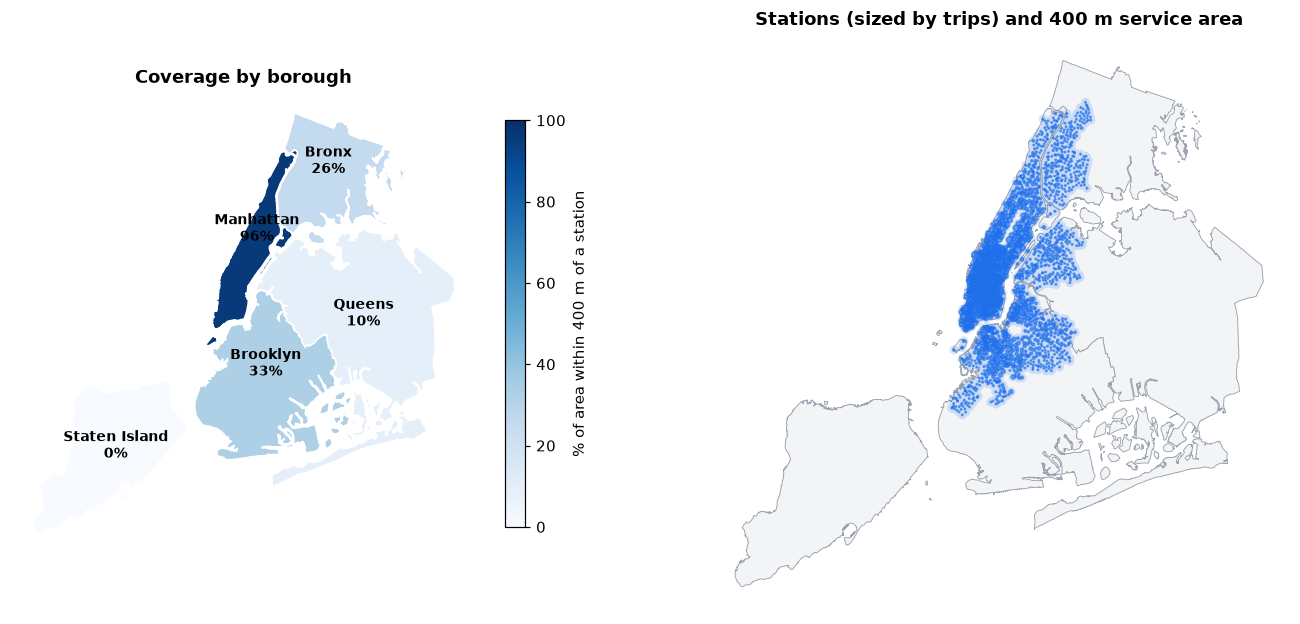

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(15, 8))
b3857 = b_utm.to_crs(3857)
b3857.plot(ax=axes[0], column="coverage_pct", cmap="Blues", vmin=0, vmax=100, edgecolor="white", lw=1,
           legend=True, legend_kwds={"label": "% of area within 400 m of a station", "shrink": 0.6})
for _, r in b3857.iterrows():
    p = r.geometry.representative_point()
    axes[0].annotate(f"{r['name']}\n{r.coverage_pct:.0f}%", (p.x, p.y), ha="center", fontsize=9, fontweight="bold")
axes[0].set_title("Coverage by borough")

pts = gst.dropna(subset=["borough"]).to_crs(3857)
b3857.plot(ax=axes[1], color="#f3f4f6", edgecolor="#9ca3af", lw=0.6)
gpd.GeoSeries([coverage], crs=utm).to_crs(3857).plot(ax=axes[1], color=ACCENT, alpha=0.18)
pts.plot(ax=axes[1], markersize=np.clip(pts.starts / 4000, 1, 40), color=ACCENT, alpha=0.6)
axes[1].set_title("Stations (sized by trips) and 400 m service area")
for ax in axes:
    ax.set_axis_off()
save(fig, "coverage_map")

## 9. Flows: where bikes go

Origin-destination counts show the busiest corridors, which stations drain or fill up
(and so need rebalancing trucks), and how rarely riders cross borough lines.

In [23]:
print("Busiest corridors (one direction):")
print(od.head(10).to_string(index=False))

net_flow = stations.assign(net=stations.ends - stations.starts).set_index("name")["net"]
print("\nStations losing the most bikes over the year (more trips start than end):")
print(net_flow.nsmallest(5).to_string())
print("\nStations gaining the most bikes:")
print(net_flow.nlargest(5).to_string())

Busiest corridors (one direction):
                       origin                 destination  trips
              W 21 St & 6 Ave             9 Ave & W 22 St   6345
              1 Ave & E 62 St             1 Ave & E 68 St   5826
       Norfolk St & Broome St         Henry St & Grand St   4883
        West St & Chambers St Pier 40 - Hudson River Park   4584
        Yankee Ferry Terminal            Soissons Landing   4550
North Moore St & Greenwich St        Vesey St & Church St   4523
              W 21 St & 6 Ave            W 22 St & 10 Ave   4410
          Henry St & Grand St      Norfolk St & Broome St   4323
             Soissons Landing       Yankee Ferry Terminal   4297
  Pier 40 - Hudson River Park       West St & Chambers St   4222

Stations losing the most bikes over the year (more trips start than end):
name
Broadway & W 56 St             -5796
Plaza St East & Flatbush Ave   -4109
Broadway & W 53 St             -3863
Broadway & W 58 St             -3731
Broadway & W 37 St    

destination   Bronx  Brooklyn  Manhattan   Queens
origin                                           
Bronx        543470        25      70913      602
Brooklyn         97   5356764     447139   123514
Manhattan     71771    474089   19398707    90916
Queens          464    130766      91179  1009173

Cross-borough share of trips: 5.4%


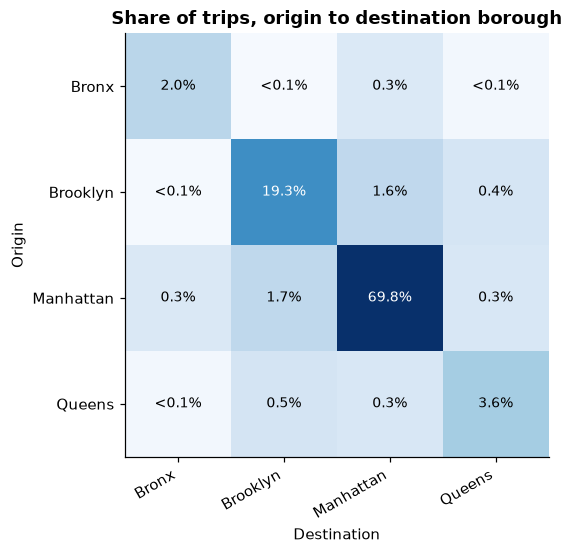

In [24]:
boro_of = gst.set_index("name")["borough"]
flows = od.assign(o=od.origin.map(boro_of), d=od.destination.map(boro_of)).dropna(subset=["o", "d"])
matrix = flows.pivot_table(index="o", columns="d", values="trips", aggfunc="sum", fill_value=0)
matrix.index.name, matrix.columns.name = "origin", "destination"
cross = 1 - np.trace(matrix.values) / matrix.values.sum()
print(matrix.to_string())
print(f"\nCross-borough share of trips: {cross:.1%}")

fig, ax = plt.subplots(figsize=(6.5, 5))
share = matrix / matrix.values.sum() * 100
from matplotlib.colors import PowerNorm
ax.imshow(share, cmap="Blues", norm=PowerNorm(0.35, vmin=0, vmax=share.values.max()))
ax.set_xticks(range(len(matrix.columns)), matrix.columns, rotation=30, ha="right")
ax.set_yticks(range(len(matrix.index)), matrix.index)
for i in range(len(matrix.index)):
    for j in range(len(matrix.columns)):
        v = share.iat[i, j]
        ax.text(j, i, f"{v:.1f}%" if v >= 0.1 else "<0.1%", ha="center", va="center",
                color="white" if v > 5 else "black", fontsize=9)
ax.set_xlabel("Destination")
ax.set_ylabel("Origin")
ax.grid(False)
ax.set_title("Share of trips, origin to destination borough")
save(fig, "borough_flows")

## 10. Findings and recommendations

**1. Demand is seasonal and forecastable a week ahead, up to the weather.** August averaged 3.5x
January's trips, with a stable weekly cycle on top (Wednesday +10%, Sunday -17%). Over 30 weeks of
backtesting SARIMA and a simple 7-day moving average were effectively tied (both ~22.5% MAPE; SARIMA
slightly lower MAE), ahead of the 30-day average and seasonal naive (~27%). The extra model complexity
buys little. The remaining error is mostly weather, which none of these models can see,
and the holiday-week holdout from the original assignment (65% error) was far harder than a typical week.
*Recommendation:* scale active fleet and staff by a rolling 30-day demand trigger rather than fixed
calendar dates, and plan holiday weeks by hand: every model misses them.

**2. Two rider groups with different needs.** Weekday demand peaks at 8 AM and 5-6 PM (commuting);
weekends have a single afternoon peak (leisure). Casual riders are a much larger share in summer
and on weekends.
*Recommendation:* sell commuters a frictionless monthly membership; use time-of-day pricing for
peak weekend leisure demand rather than location-based surcharges, which carry equity risk.

**3. The network is concentrated in Manhattan.** Manhattan is almost fully covered and produces most
trips; Queens and the Bronx are mostly outside walking distance of a dock, and Staten Island has no
stations. Fewer than 1 in 10 trips crosses a borough line.
*Recommendation:* pilot expansion in the least-covered parts of Brooklyn, Queens and the Bronx
with a small fleet and lower fares to measure latent demand before full rollout.

**4. Rebalancing is predictable.** Net flow is lopsided at a few stations every day.
*Recommendation:* route rebalancing trucks to the biggest net senders before the 7 AM peak and to the
biggest net receivers before 5 PM.

### Limitations
- **No weather data.** Rain and temperature drive most day-to-day surprises; adding them is the obvious next step.
- **One year of history**, so annual seasonality is learned only as trend and can't be modelled directly.
- **Completed trips only.** The data can't show riders who wanted a bike and found none (latent demand).
- **Coverage is straight-line distance**, not walking distance along streets.